<div dir="rtl">

# הרצאה 1: משוואות פרידמן, גיל ומרחקים

**מה במחברת.** פותרים נומרית את משוואת פרידמן, מחשבים את גיל היקום ואת ההסחה שבה התחילה התאוצה, ובונים את כל המרחקים הקוסמולוגיים ($D_C, D_M, D_L, D_A$). בסוף יש ארבעה תרגילים פתורים נוספים.

**משוואת פרידמן** בצורה חסרת ממדים:
$$E^2(z)\equiv\frac{H^2(z)}{H_0^2}=\Omega_r(1+z)^4+\Omega_m(1+z)^3+\Omega_k(1+z)^2+\Omega_\Lambda,\qquad \Omega_k=1-\Omega_r-\Omega_m-\Omega_\Lambda .$$

ערכי ברירת המחדל: Planck 2018 ($h=0.674$, $\Omega_m=0.315$).

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq, minimize_scalar

plt.rcParams.update({"font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
c = 299792.458            # km/s

h = 0.674; H0 = 100*h           # km/s/Mpc
Om0, Or0 = 0.315, 9.1e-5        # Or: photons + 3 massless neutrinos
OL0 = 1 - Om0 - Or0
DH = c/H0                       # Hubble distance [Mpc]
tH = 977.8/H0                   # Hubble time 1/H0 [Gyr]
print(f"c/H0 = {DH:.0f} Mpc,  1/H0 = {tH:.2f} Gyr")

def E(z, Om=Om0, OL=OL0, Or=Or0):
    Ok = 1 - Om - OL - Or
    return np.sqrt(Or*(1+z)**4 + Om*(1+z)**3 + Ok*(1+z)**2 + OL)

c/H0 = 4448 Mpc,  1/H0 = 14.51 Gyr


<div dir="rtl">

## 1. הפתרון $a(t)$ לחמישה יקומים

כותבים $\dot a = H_0\,a\,E(a)$ ומשלבים את $t(a)=\int_0^a \frac{da'}{a'H(a')}$. ביקום סגור ($\Omega_m>1$, $\Omega_\Lambda=0$) הפונקציה $a(t)$ מגיעה למקסימום וחוזרת, ולכן שם פותרים מד"ר של סדר שני: $\ddot a = -\tfrac12 H_0^2\,\Omega_m/a^2 + H_0^2\Omega_\Lambda a$.

</div>

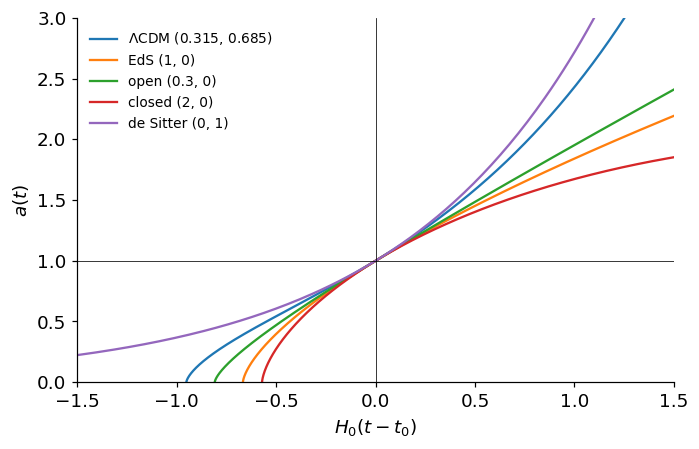

In [2]:
def a_of_t(Om, OL, t_max=3.0, Or=0.0):
    # second-order Friedmann eq. in units H0=1: a'' = -Om/(2a^2) - Or/a^3 + OL a
    def rhs(t, y):
        a, ad = y
        return [ad, -0.5*Om/a**2 - Or/a**3 + OL*a]
    # start at small a on the matter-dominated attractor; t from the EdS-like series
    a0 = 1e-3; Ok = 1 - Om - OL - Or
    ad0 = np.sqrt(Om/a0 + Ok + OL*a0**2)
    t0 = (2/3)*a0**1.5/np.sqrt(Om) if Om > 0 else a0/ad0
    hit0 = lambda t, y: y[0] - 1e-3; hit0.terminal = True; hit0.direction = -1
    sol = solve_ivp(rhs, [t0, t_max], [a0, ad0], events=hit0, max_step=1e-3, rtol=1e-9)
    return sol.t, sol.y[0]

models = {r"$\Lambda$CDM (0.315, 0.685)": (0.315, 0.685),
          "EdS (1, 0)": (1.0, 0.0),
          "open (0.3, 0)": (0.3, 0.0),
          "closed (2, 0)": (2.0, 0.0),
          "de Sitter (0, 1)": (0.0, 1.0)}
fig, ax = plt.subplots(figsize=(7, 4.3))
for i, (lab, (Om, OL)) in enumerate(models.items()):
    if Om == 0:   # pure de Sitter: a = exp(t - t_today), shift so a(t_today)=1
        t = np.linspace(-3, 1.5, 300); a = np.exp(t)
        ax.plot(t, a, color=f"C{i}", label=lab); continue
    t, a = a_of_t(Om, OL)
    t_today = t[np.argmin(np.abs(a - 1)[: np.argmax(a) + 1])]   # first time a=1
    ax.plot(t - t_today, a, color=f"C{i}", label=lab)
ax.axhline(1, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlim(-1.5, 1.5); ax.set_ylim(0, 3)
ax.set_xlabel(r"$H_0(t-t_0)$"); ax.set_ylabel(r"$a(t)$")
ax.legend(fontsize=9, frameon=False); plt.show()

<div dir="rtl">

**מה רואים.** כל העקומות עוברות דרך $(0,1)$ עם אותו שיפוע ($H_0$), אבל נבדלות בעבר: ככל שיש יותר חומר, היקום האט יותר, ולכן המפץ (החיתוך עם $a=0$) קרוב יותר להיום. היקום הסגור קורס חזרה. $\Lambda$CDM מתעקם כלפי מעלה, וזו התאוצה.

</div>

<div dir="rtl">

## 2. גיל היקום

$$t_0=\frac{1}{H_0}\int_0^\infty\frac{dz}{(1+z)E(z)} .$$
ל-$\Lambda$CDM שטוח (בלי קרינה) יש נוסחה סגורה: $t_0=\frac{2}{3H_0\sqrt{\Omega_\Lambda}}\,\mathrm{arsinh}\sqrt{\Omega_\Lambda/\Omega_m}$.

</div>

LCDM Planck:  t0 = 13.791 Gyr (numeric, with radiation)   13.797 Gyr (closed form, no radiation)
EdS:          t0 = 9.672 Gyr   (= 2/3 /H0 = 9.672)
open Om=0.3:  t0 = 11.734 Gyr


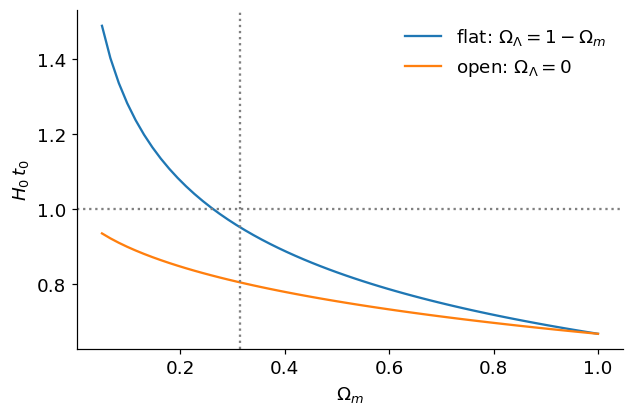

In [3]:
def age(z=0.0, **kw):
    # age of the universe at redshift z [Gyr]
    return tH*quad(lambda x: 1/((1+x)*E(x, **kw)), z, np.inf, limit=200)[0]

t0_num = age()
t0_an = tH*2/(3*np.sqrt(OL0))*np.arcsinh(np.sqrt(OL0/Om0))
print(f"LCDM Planck:  t0 = {t0_num:.3f} Gyr (numeric, with radiation)   {t0_an:.3f} Gyr (closed form, no radiation)")
print(f"EdS:          t0 = {age(Om=1, OL=0, Or=0):.3f} Gyr   (= 2/3 /H0 = {2/3*tH:.3f})")
print(f"open Om=0.3:  t0 = {age(Om=0.3, OL=0, Or=0):.3f} Gyr")

Oms = np.linspace(0.05, 1.0, 60)
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(Oms, [age(Om=o, OL=1-o, Or=0)*H0/977.8 for o in Oms], "C0", label=r"flat: $\Omega_\Lambda=1-\Omega_m$")
ax.plot(Oms, [age(Om=o, OL=0, Or=0)*H0/977.8 for o in Oms], "C1", label=r"open: $\Omega_\Lambda=0$")
ax.axhline(1, color="gray", ls=":"); ax.axvline(Om0, color="gray", ls=":")
ax.set_xlabel(r"$\Omega_m$"); ax.set_ylabel(r"$H_0\,t_0$"); ax.legend(frameon=False); plt.show()

<div dir="rtl">

**בעיית הגיל.** בלי $\Lambda$, $H_0t_0<1$ תמיד, ועם $h\approx0.7$ מקבלים יקום צעיר מהכוכבים העתיקים ($\sim13\,$Gyr). קבוע קוסמולוגי פותר את זה: ב-$\Omega_m\approx0.3$ שטוח, $H_0t_0\approx0.95$.

</div>

<div dir="rtl">

## 3. תאוצה: $q(z)$ ו-$z_{\rm acc}$

פרמטר ההאטה $q=-\ddot a a/\dot a^2$. ל-$\Lambda$CDM שטוח: $q(z)=\frac{\Omega_m(1+z)^3/2-\Omega_\Lambda}{E^2(z)}$, והתאוצה מתחילה ב-$(1+z_{\rm acc})^3=2\Omega_\Lambda/\Omega_m$.

</div>

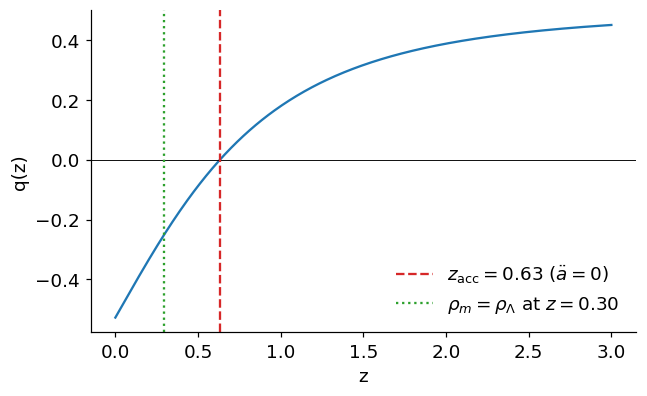

q0 = -0.527


In [4]:
z = np.linspace(0, 3, 400)
q = (0.5*Om0*(1+z)**3 - OL0)/E(z, Or=0)**2
z_acc = (2*OL0/Om0)**(1/3) - 1
z_eq_mL = (OL0/Om0)**(1/3) - 1
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(z, q, "C0"); ax.axhline(0, color="k", lw=0.6)
ax.axvline(z_acc, color="C3", ls="--", label=rf"$z_{{\rm acc}}={z_acc:.2f}$ ($\ddot a=0$)")
ax.axvline(z_eq_mL, color="C2", ls=":", label=rf"$\rho_m=\rho_\Lambda$ at $z={z_eq_mL:.2f}$")
ax.set_xlabel("z"); ax.set_ylabel("q(z)"); ax.legend(frameon=False); plt.show()
print(f"q0 = {q[0]:.3f}")

<div dir="rtl">

## 4. מרחקים

$$D_C=\frac{c}{H_0}\int_0^z\frac{dz'}{E(z')},\qquad D_M=\begin{cases}\frac{c}{H_0\sqrt{\Omega_k}}\sinh\!\big(\sqrt{\Omega_k}\,D_CH_0/c\big) & \Omega_k>0\\ D_C & \Omega_k=0\\ \frac{c}{H_0\sqrt{-\Omega_k}}\sin\!\big(\sqrt{-\Omega_k}\,D_CH_0/c\big) & \Omega_k<0\end{cases}$$
$$D_L=(1+z)D_M,\qquad D_A=\frac{D_M}{1+z},\qquad t_{\rm lb}=\frac{1}{H_0}\int_0^z\frac{dz'}{(1+z')E(z')} .$$

</div>

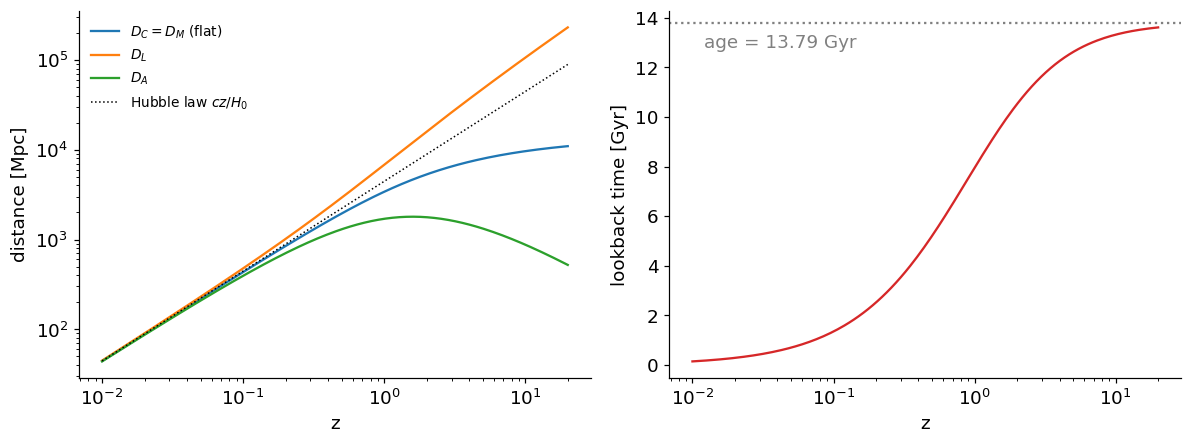

z= 0.1:  D_M=    434  D_L=    478  D_A=   395 Mpc   lookback= 1.35 Gyr
z= 0.5:  D_M=   1951  D_L=   2927  D_A=  1301 Mpc   lookback= 5.21 Gyr
z=   1:  D_M=   3401  D_L=   6802  D_A=  1700 Mpc   lookback= 7.95 Gyr
z=   2:  D_M=   5311  D_L=  15934  D_A=  1770 Mpc   lookback=10.52 Gyr
z=   3:  D_M=   6505  D_L=  26018  D_A=  1626 Mpc   lookback=11.65 Gyr


In [5]:
def D_C(z, **kw):
    return DH*quad(lambda x: 1/E(x, **kw), 0, z, limit=200)[0]

def D_M(z, Om=Om0, OL=OL0, Or=Or0):
    Ok = 1 - Om - OL - Or; x = D_C(z, Om=Om, OL=OL, Or=Or)/DH
    if abs(Ok) < 1e-8: return DH*x
    if Ok > 0: return DH*np.sinh(np.sqrt(Ok)*x)/np.sqrt(Ok)
    return DH*np.sin(np.sqrt(-Ok)*x)/np.sqrt(-Ok)

D_L = lambda z, **kw: (1+z)*D_M(z, **kw)
D_A = lambda z, **kw: D_M(z, **kw)/(1+z)
lookback = lambda z, **kw: tH*quad(lambda x: 1/((1+x)*E(x, **kw)), 0, z)[0]

zz = np.logspace(-2, np.log10(20), 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for f, lab, col in [(D_C, r"$D_C=D_M$ (flat)", "C0"), (D_L, r"$D_L$", "C1"), (D_A, r"$D_A$", "C2")]:
    ax[0].loglog(zz, [f(x) for x in zz], col, label=lab)
ax[0].loglog(zz, DH*zz, "k:", lw=1, label=r"Hubble law $cz/H_0$")
ax[0].set_xlabel("z"); ax[0].set_ylabel("distance [Mpc]"); ax[0].legend(frameon=False, fontsize=9)
ax[1].plot(zz, [lookback(x) for x in zz], "C3")
ax[1].axhline(age(), color="gray", ls=":"); ax[1].text(0.012, age()-1.0, f"age = {age():.2f} Gyr", color="gray")
ax[1].set_xscale("log"); ax[1].set_xlabel("z"); ax[1].set_ylabel("lookback time [Gyr]")
fig.tight_layout(); plt.show()

for z_ in (0.1, 0.5, 1, 2, 3):
    print(f"z={z_:>4}:  D_M={D_M(z_):7.0f}  D_L={D_L(z_):7.0f}  D_A={D_A(z_):6.0f} Mpc   lookback={lookback(z_):5.2f} Gyr")

<div dir="rtl">

**$D_A$ לא מונוטוני.** מעבר ל-$z\approx1.6$ עצמים *גדלים* בשמיים ככל שהם רחוקים יותר: האור יצא כשהיקום היה קטן, והעצם תפס זווית גדולה יותר. נבדוק את זה ישירות:

</div>

$\Lambda$CDM  : D_A max at z = 1.59, theta_min(10 kpc) = 1.15 arcsec
EdS           : D_A max at z = 1.25, theta_min(10 kpc) = 1.57 arcsec


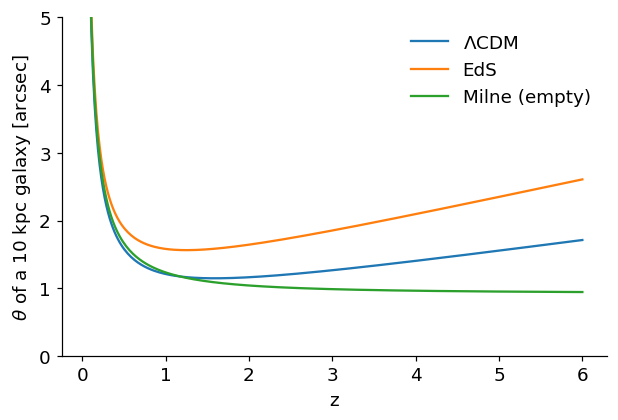

In [6]:
kpc10 = 0.010   # Mpc
zz = np.linspace(0.05, 6, 300)
models_dA = {r"$\Lambda$CDM": dict(), "EdS": dict(Om=1, OL=0, Or=0), "Milne (empty)": dict(Om=0, OL=0, Or=0)}
fig, ax = plt.subplots(figsize=(6.4, 4))
for i, (lab, kw) in enumerate(models_dA.items()):
    th = [kpc10/D_A(x, **kw)*206265 for x in zz]
    ax.plot(zz, th, f"C{i}", label=lab)
    r = minimize_scalar(lambda x: -D_A(x, **kw), bounds=(0.2, 50), method="bounded")
    if r.x < 49: print(f"{lab:14s}: D_A max at z = {r.x:.2f}, theta_min(10 kpc) = {kpc10/D_A(r.x, **kw)*206265:.2f} arcsec")
ax.set_xlabel("z"); ax.set_ylabel(r"$\theta$ of a 10 kpc galaxy [arcsec]")
ax.set_ylim(0, 5); ax.legend(frameon=False); plt.show()

<div dir="rtl">

---
# תרגילים פתורים נוספים

### תרגיל א: יקום סגור, מקסימום התפשטות וקריסה
ל-$\Omega_m=2$, $\Omega_\Lambda=0$ יש פתרון פרמטרי (ציקלואידה): $a=\frac{\Omega_m}{2(\Omega_m-1)}(1-\cos\eta)$, $H_0t=\frac{\Omega_m}{2(\Omega_m-1)^{3/2}}(\eta-\sin\eta)$. מצאו את $a_{\max}$, את זמן מקסימום ההתפשטות ואת זמן הקריסה, והשוו לפתרון הנומרי.

**פתרון.** $a_{\max}$ ב-$\eta=\pi$: $a_{\max}=\Omega_m/(\Omega_m-1)=2$. $H_0t_{\max}=\pi\Omega_m/[2(\Omega_m-1)^{3/2}]=\pi$, והקריסה ב-$2\pi$. היום ($a=1$): $\cos\eta=0$, $\eta=\pi/2$, ולכן $H_0t_0=\pi/2-1=0.571$.

</div>

numeric:  a_max = 1.9999 at H0 t = 3.1415;  crunch at H0 t = 6.283
analytic: a_max = 2.0000 at H0 t = 3.1416;  crunch at H0 t = 6.283;  H0 t0 = 0.5708


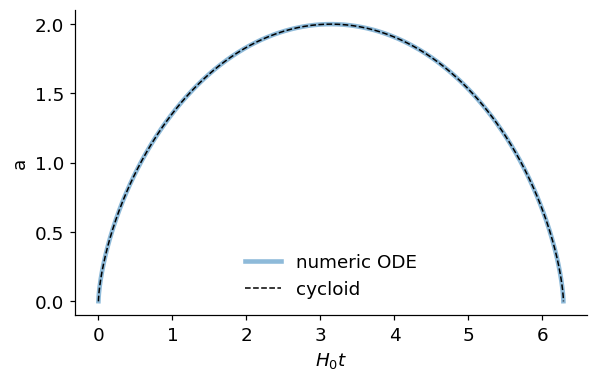

In [7]:
Om = 2.0
t, a = a_of_t(Om, 0.0, t_max=8)
A = Om/(2*(Om-1)); B = Om/(2*(Om-1)**1.5)
eta = np.linspace(0, 2*np.pi, 400)
print(f"numeric:  a_max = {a.max():.4f} at H0 t = {t[np.argmax(a)]:.4f};  crunch at H0 t = {t[-1]:.3f}")
print(f"analytic: a_max = {2*A:.4f} at H0 t = {np.pi*B:.4f};  crunch at H0 t = {2*np.pi*B:.3f};  H0 t0 = {B*(np.pi/2-1):.4f}")
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(t, a, "C0", lw=3, alpha=0.5, label="numeric ODE")
ax.plot(B*(eta-np.sin(eta)), A*(1-np.cos(eta)), "k--", lw=1, label="cycloid")
ax.set_xlabel(r"$H_0 t$"); ax.set_ylabel("a"); ax.legend(frameon=False); plt.show()

<div dir="rtl">

### תרגיל ב: שוויון קרינה-חומר
מ-$\Omega_mh^2=0.143$ ו-$\Omega_rh^2=4.15\times10^{-5}$: חשבו את $z_{\rm eq}$, את הטמפרטורה של ה-CMB אז, ואת גיל היקום בשוויון.

**פתרון.** $1+z_{\rm eq}=\Omega_m/\Omega_r=3446$; $T=T_0(1+z)=9.4\times10^3\,$K. לגיל: בעידן קרינה+חומר יש פתרון סגור, $H_0t=\frac{2}{3}\frac{a_{\rm eq}^{3/2}}{\sqrt{\Omega_m}}\big[(x-2)\sqrt{x+1}+2\big]$ עם $x=a/a_{\rm eq}$, וב-$x=1$ זה $\approx51$ אלף שנה.

</div>

In [8]:
Omh2, Orh2 = 0.143, 4.15e-5
zeq = Omh2/Orh2 - 1; aeq = 1/(1+zeq)
print(f"z_eq = {zeq:.0f},  T_eq = {2.7255*(1+zeq):.0f} K")
Om_, Or_ = Omh2/h**2, Orh2/h**2
t_eq_closed = tH*(2/3)*aeq**1.5/np.sqrt(Om_)*((1-2)*np.sqrt(2)+2)
t_eq_num = age(zeq, Om=Om_, OL=1-Om_-Or_, Or=Or_)
print(f"t_eq = {t_eq_closed*1e9/1e3:.1f} kyr (closed form),  {t_eq_num*1e9/1e3:.1f} kyr (numeric, incl. Lambda)")

z_eq = 3445,  T_eq = 9391 K
t_eq = 49.9 kyr (closed form),  49.9 kyr (numeric, incl. Lambda)


<div dir="rtl">

### תרגיל ג: גיל היקום ב-$z=10$ וב-$z=1100$
מה היה גיל היקום כשנפלטה קרינת הרקע ($z\approx1100$) וכשנוצרו הגלקסיות הראשונות ש-JWST רואה ($z\approx10$)? בעידן החומר $t(z)\approx\frac{2}{3H_0\sqrt{\Omega_m}}(1+z)^{-3/2}$. כמה טוב הקירוב?

</div>

In [9]:
for z_ in (1100, 10, 3, 1):
    approx = tH*2/(3*np.sqrt(Om0))*(1+z_)**-1.5
    print(f"z={z_:>5}:  t = {age(z_)*1e3:9.2f} Myr (numeric)   {approx*1e3:9.2f} Myr (matter-only)")

z= 1100:  t =      0.37 Myr (numeric)        0.47 Myr (matter-only)
z=   10:  t =    470.12 Myr (numeric)      472.34 Myr (matter-only)
z=    3:  t =   2138.48 Myr (numeric)     2154.04 Myr (matter-only)
z=    1:  t =   5840.85 Myr (numeric)     6092.54 Myr (matter-only)


<div dir="rtl">

**מסקנה.** ב-$z=10$ הקירוב מצוין (היקום בן כ-470 מיליון שנה). ב-$z=1100$ הקירוב מגזים בכ-25% (470 במקום 370 אלף שנה), כי הקרינה עוד תרמה ל-$H$. ב-$z=1$ הוא טועה ב-4%, כי $\Lambda$ כבר לא זניח.

### תרגיל ד: עד איפה תקף חוק האבל?
עד איזו הסחה $D_L\approx cz/H_0$ מדויק ל-1%? ומה עם הקירוב מסדר שני $D_L\approx\frac{c}{H_0}\big[z+\tfrac12(1-q_0)z^2\big]$?

</div>

In [10]:
q0 = 0.5*Om0 - OL0
err1 = lambda z: DH*z/D_L(z) - 1
err2 = lambda z: DH*(z + 0.5*(1-q0)*z**2)/D_L(z) - 1
z1 = brentq(lambda z: abs(err1(z)) - 0.01, 1e-3, 1)
z2 = brentq(lambda z: abs(err2(z)) - 0.01, 1e-3, 2)
print(f"q0 = {q0:.3f}")
print(f"Hubble law good to 1% for z < {z1:.3f}   (v < {c*z1:.0f} km/s)")
print(f"2nd-order expansion good to 1% for z < {z2:.2f}")

q0 = -0.527
Hubble law good to 1% for z < 0.013   (v < 3985 km/s)
2nd-order expansion good to 1% for z < 0.20


<div dir="rtl">

**מסקנה.** חוק האבל הליניארי מדויק ל-1% רק עד $z\approx0.013$ (כ-4000 km/s). ההרחבה מסדר שני, עם $q_0$, מחזיקה עד $z\approx0.2$. לכן מדידות $H_0$ עם סופרנובות ($0.023<z<0.15$) משתמשות בהרחבה עם $q_0$ ו-$j_0$.

</div>